In [1]:
import sys
sys.path.append('..')   # lets the notebook find your src folder
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import read_sql
from src.cleaning import load_clean_orders
sns.set_theme(style='whitegrid')

raw = read_sql('SELECT * FROM vw_orders_clean')   # before filling missing values
df = load_clean_orders()                          # after cleaning
print(df.shape)
df.head()

(96470, 16)


,order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_days,items_value,freight_total,n_items,payment_total,installments,main_payment_type,review_score,no_review_flag
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,-9,7,58.90,13.29,1,72.19,2.0,credit_card,5.0,0
1,00054e8431b9d7675808bcb819fb4a32,635d9ac1680f03288e72ada3a1035803,SP,2017-12-10 11:53:48,2017-12-18 22:03:38,2018-01-04,-17,8,19.90,11.85,1,31.75,1.0,credit_card,4.0,0
2,000576fe39319847cbb9d288c5617fa6,fda4476abb6307ab3c415b7e6d026526,SP,2018-07-04 12:08:27,2018-07-09 14:04:07,2018-07-25,-16,5,810.00,70.75,1,880.75,10.0,credit_card,5.0,0
3,0005a1a1728c9d785b8e2b08b904576c,639d23421f5517f69d0c3d6e6564cf0e,SP,2018-03-19 18:40:33,2018-03-29 18:17:31,2018-03-29,0,10,145.95,11.65,1,157.60,3.0,credit_card,1.0,0
4,00061f2a7bc09da83e415a52dc8a4af1,107e6259485efac66428a56f10801f4f,SP,2018-03-24 22:16:10,2018-03-29 00:04:19,2018-04-09,-11,5,59.99,8.88,1,68.87,3.0,credit_card,5.0,0


In [2]:
# 1. Missing values and data types
print(raw.isna().mean().round(3))
raw.dtypes

order_id                         0.000
customer_unique_id               0.000
customer_state                   0.000
order_purchase_timestamp         0.000
order_delivered_customer_date    0.000
order_estimated_delivery_date    0.000
delivery_delay_days              0.000
delivery_days                    0.000
items_value                      0.000
freight_total                    0.000
n_items                          0.000
payment_total                    0.000
installments                     0.000
main_payment_type                0.000
review_score                     0.007
dtype: float64


order_id                                    str
customer_unique_id                          str
customer_state                              str
order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
delivery_delay_days                       int64
delivery_days                             int64
items_value                             float64
freight_total                           float64
n_items                                   int64
payment_total                           float64
installments                            float64
main_payment_type                           str
review_score                            float64
dtype: object

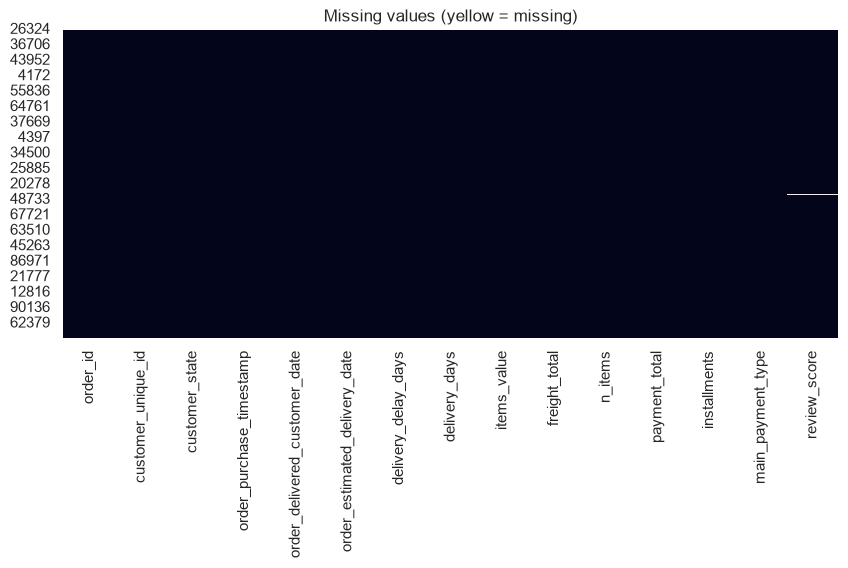

In [3]:
# 1b. Missing-value heatmap (sample for speed)
plt.figure(figsize=(10, 4))
sns.heatmap(raw.sample(5000, random_state=1).isna(), cbar=False)
plt.title('Missing values (yellow = missing)')
plt.savefig('../reports/figures/missing_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

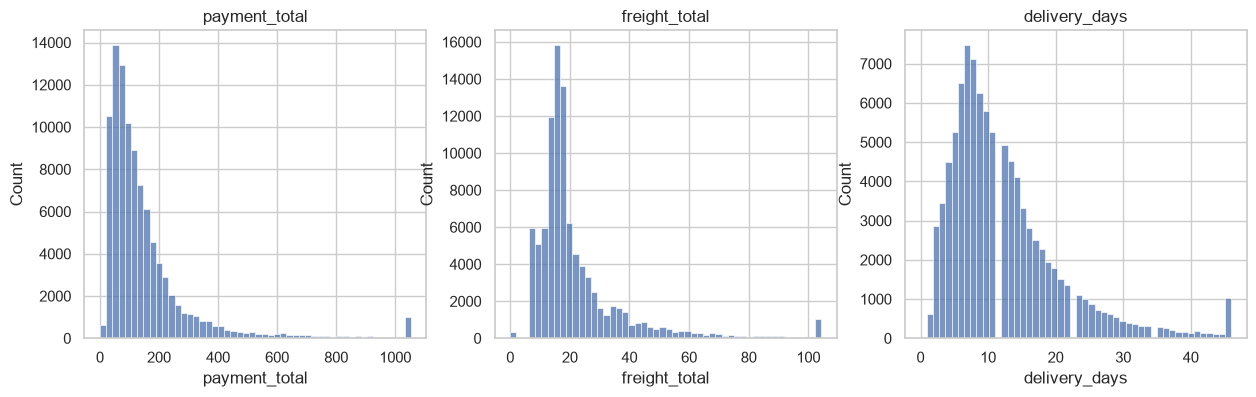

In [4]:
# 2. Distributions: order value, freight, delivery days
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ['payment_total', 'freight_total', 'delivery_days']):
    sns.histplot(df[c].clip(upper=df[c].quantile(0.99)), bins=50, ax=a)
    a.set_title(c)
plt.savefig('../reports/figures/distributions.png', dpi=150, bbox_inches='tight')
plt.show()

1    0.969995
2    0.027563
3    0.001939
4    0.000300
5    0.000096
Name: proportion, dtype: float64


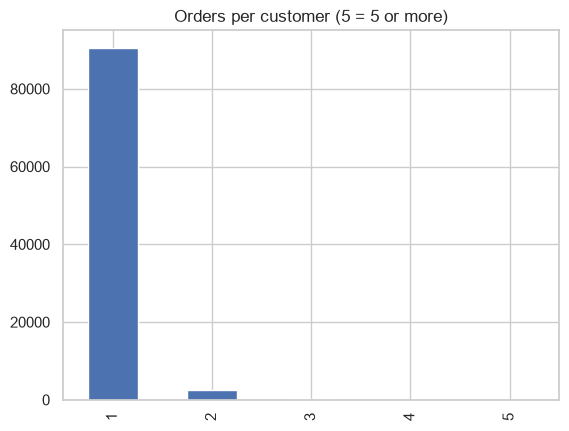

In [5]:
# 3. Orders per customer (shows the ~97% one-time buyers)
opc = df.groupby('customer_unique_id').size()
print(opc.value_counts(normalize=True).head())
opc.clip(upper=5).value_counts().sort_index().plot(kind='bar', title='Orders per customer (5 = 5 or more)')
plt.savefig('../reports/figures/orders_per_customer.png', dpi=150, bbox_inches='tight')
plt.show()

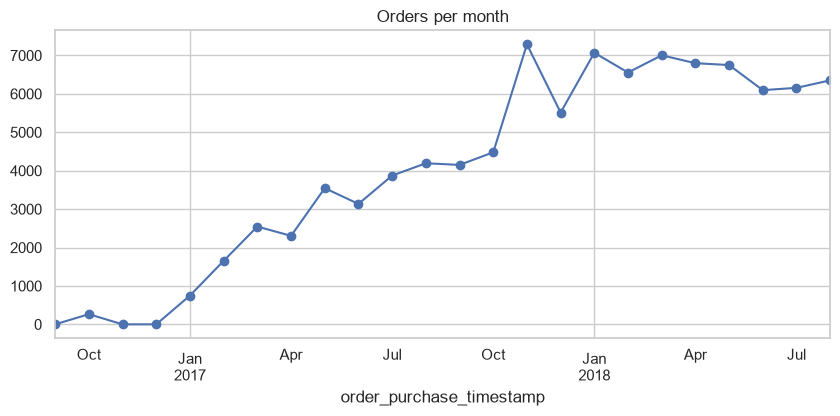

In [6]:
# 4. Orders over time (look for the Nov 2017 Black Friday spike)
monthly = df.set_index('order_purchase_timestamp').resample('MS').size()
monthly.plot(figsize=(10, 4), marker='o', title='Orders per month')
plt.savefig('../reports/figures/orders_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

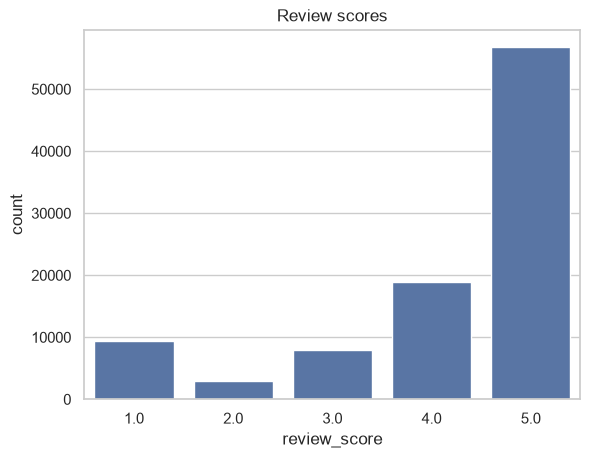

In [7]:
# 5. Review score distribution (only real reviews)
real = df[df.no_review_flag == 0]
sns.countplot(x=real.review_score)
plt.title('Review scores')
plt.savefig('../reports/figures/review_scores.png', dpi=150, bbox_inches='tight')
plt.show()

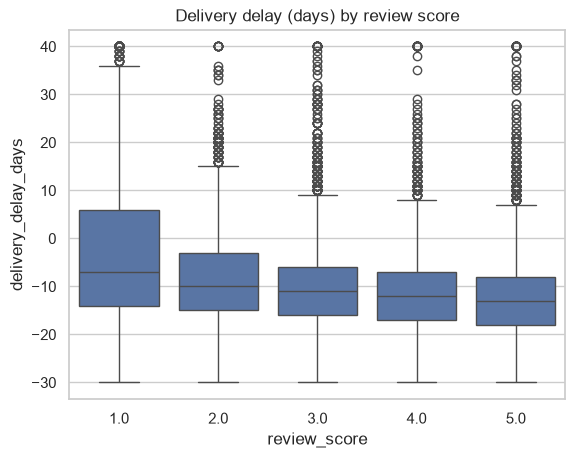

In [8]:
# 6. Delivery delay vs review score
sns.boxplot(data=real, x='review_score', y=real.delivery_delay_days.clip(-30, 40))
plt.title('Delivery delay (days) by review score')
plt.savefig('../reports/figures/delay_vs_review.png', dpi=150, bbox_inches='tight')
plt.show()

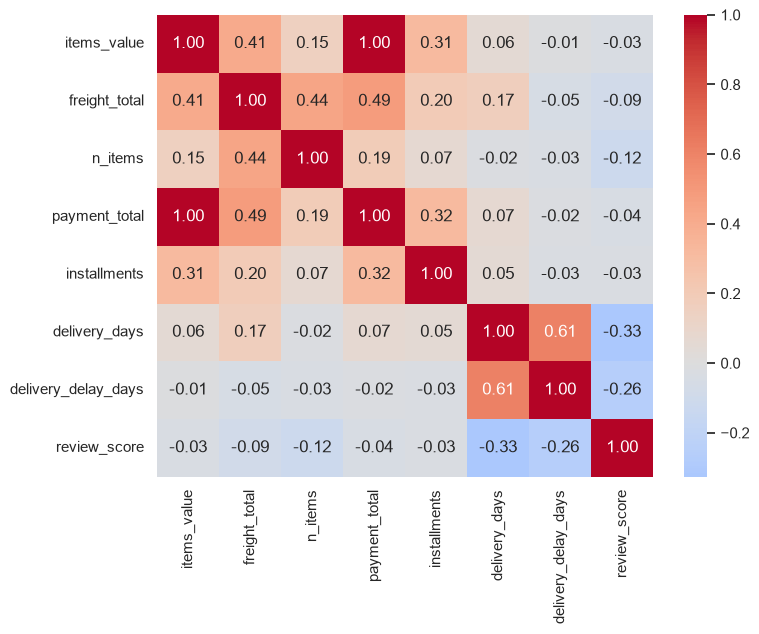

In [9]:
# 7. Correlation heatmap of numeric columns
num = df[['items_value', 'freight_total', 'n_items', 'payment_total', 'installments', 'delivery_days', 'delivery_delay_days', 'review_score']]
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.savefig('../reports/figures/correlation.png', dpi=150, bbox_inches='tight')
plt.show()